In [86]:
#upload the Library
import pandas as pd #for data analysis and manipulation
import numpy as np #for numerical calculation
import seaborn as sns #for data visualization
import matplotlib.pyplot as plt #for data visualization

In [87]:
# Choose the used-cars CSV file from your computer
from google.colab import files

uploaded = files.upload()
csv_file = next(iter(uploaded))
df = pd.read_csv(csv_file)

print('city:', df.city)
df.head()

Saving uncleaned_used_cars_eda (1).csv to uncleaned_used_cars_eda (1) (2).csv
city: 0      hyderabad
1            Hyd
2      Bangalore
3      Bengaluru
4         Mumbai
         ...    
118    New Delhi
119    Hyderabad
120          Hyd
121        Delhi
122       Mumbai
Name: city, Length: 123, dtype: object


,car_id,brand,model,year,price_inr,km_driven,fuel_type,transmission,owner_type,mileage_kmpl,engine_cc,city,insurance_valid,seller_rating,listed_date
0,CAR001,maruti,Baleno,2009,236000.0,13300,petrol,manual,1st,12.9,1000.0,hyderabad,Yes,3.1,02/02/2026
1,CAR002,MARUTI,i20,2010,292000.0,17600,Diesel,Automatic,Second,13.8,1200.0,Hyd,Yes,3.2,03/03/2026
2,CAR003,Hyundai,Creta,2011,348000.0,21900,diesel,Auto,2nd,14.7,1400.0,Bangalore,Yes,3.3,2026-04-04
3,CAR004,hyundai,Nexon,2012,404000.0,26200,CNG,AUTOMATIC,Third,15.6,1600.0,Bengaluru,NO,3.4,05/05/2026
4,CAR005,Tata,XUV300,2013,460000.0,30500,Electric,Manual,3rd,16.5,1800.0,Mumbai,Yes,3.5,06/06/2026


In [88]:
numeric_cols = df.select_dtypes(include = "number")
print(numeric_cols)

     price_inr  mileage_kmpl  engine_cc  seller_rating
0     236000.0          12.9     1000.0            3.1
1     292000.0          13.8     1200.0            3.2
2     348000.0          14.7     1400.0            3.3
3     404000.0          15.6     1600.0            3.4
4     460000.0          16.5     1800.0            3.5
..         ...           ...        ...            ...
118  1261000.0          20.1     2200.0            4.4
119   189000.0          12.0      800.0            4.5
120   789000.0          13.8     1600.0            4.2
121   865000.0          19.2     2000.0            4.7
122   366000.0          16.5     1400.0            4.2

[123 rows x 4 columns]


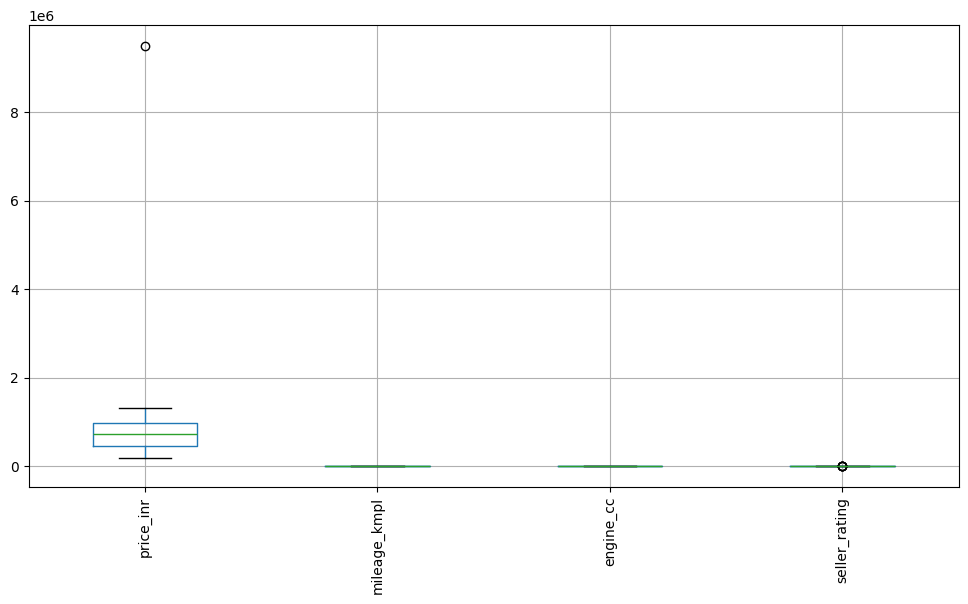

In [89]:
numeric_cols.boxplot(figsize =(12,6))
plt.xticks(rotation = 90)
plt.show()

In [90]:
df.head()

,car_id,brand,model,year,price_inr,km_driven,fuel_type,transmission,owner_type,mileage_kmpl,engine_cc,city,insurance_valid,seller_rating,listed_date
0,CAR001,maruti,Baleno,2009,236000.0,13300,petrol,manual,1st,12.9,1000.0,hyderabad,Yes,3.1,02/02/2026
1,CAR002,MARUTI,i20,2010,292000.0,17600,Diesel,Automatic,Second,13.8,1200.0,Hyd,Yes,3.2,03/03/2026
2,CAR003,Hyundai,Creta,2011,348000.0,21900,diesel,Auto,2nd,14.7,1400.0,Bangalore,Yes,3.3,2026-04-04
3,CAR004,hyundai,Nexon,2012,404000.0,26200,CNG,AUTOMATIC,Third,15.6,1600.0,Bengaluru,NO,3.4,05/05/2026
4,CAR005,Tata,XUV300,2013,460000.0,30500,Electric,Manual,3rd,16.5,1800.0,Mumbai,Yes,3.5,06/06/2026


In [91]:
df.tail()

,car_id,brand,model,year,price_inr,km_driven,fuel_type,transmission,owner_type,mileage_kmpl,engine_cc,city,insurance_valid,seller_rating,listed_date
118,CAR119,Toyta,Altroz,2008,1261000.0,120800,Petrol,AUTOMATIC,3rd,20.1,2200.0,New Delhi,Yes,4.4,12/12/2026
119,CAR120,Maruti,Swift,2009,189000.0,125100,petrol,Manual,First,12.0,800.0,Hyderabad,NO,4.5,2026-01-13
120,CAR012,Maruti,i20,2020,789000.0,60600,Electric,Automatic,First,13.8,1600.0,Hyd,NO,4.2,2026-01-13
121,CAR038,NaN,Innova,2012,865000.0,39100,diesel,Auto,Second,19.2,2000.0,Delhi,Yes,4.7,12/03/2026
122,CAR075,Hyundai,XUV300,2015,366000.0,64900,Electric,Manual,2nd,16.5,1400.0,Mumbai,Yes,4.2,31/02/2025


In [92]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 123 entries, 0 to 122
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   car_id           123 non-null    object 
 1   brand            116 non-null    object 
 2   model            123 non-null    object 
 3   year             123 non-null    object 
 4   price_inr        118 non-null    float64
 5   km_driven        123 non-null    object 
 6   fuel_type        123 non-null    object 
 7   transmission     120 non-null    object 
 8   owner_type       123 non-null    object 
 9   mileage_kmpl     118 non-null    float64
 10  engine_cc        119 non-null    float64
 11  city             123 non-null    object 
 12  insurance_valid  123 non-null    object 
 13  seller_rating    123 non-null    float64
 14  listed_date      123 non-null    object 
dtypes: float64(4), object(11)
memory usage: 14.5+ KB


In [93]:
df.describe()

,price_inr,mileage_kmpl,engine_cc,seller_rating
count,1.180000e+02,118.000000,119.000000,123.000000
mean,7.984492e+05,16.118644,1507.563025,4.204065
std,8.676712e+05,2.613769,456.805352,1.091127
min,1.890000e+05,12.000000,800.000000,3.000000
25%,4.532500e+05,13.800000,1200.000000,3.600000
50%,7.285000e+05,16.500000,1600.000000,4.100000
75%,9.852500e+05,18.300000,1900.000000,4.550000
max,9.500000e+06,20.100000,2200.000000,8.700000


In [94]:
#Missing Values
df.isnull().sum()

,0
car_id,0
brand,7
model,0
year,0
price_inr,5
km_driven,0
fuel_type,0
transmission,3
owner_type,0
mileage_kmpl,5


In [95]:
# check if any duplicates
df.duplicated().sum()

np.int64(3)

In [96]:
# Remove all Duplicates
df.drop_duplicates(inplace= True)

In [97]:
# Recheck if any duplicates
df.duplicated().sum()

np.int64(0)

In [98]:
df["car_id"] = df["car_id"].fillna(df["car_id"].mode()[0])

In [99]:
df["model"] = df["model"].fillna(df["model"].mode()[0])

In [100]:
df["transmission"] = df["transmission"].fillna(df["transmission"].mode()[0])

In [101]:
df["mileage_kmpl"] = df["mileage_kmpl"].fillna(df["mileage_kmpl"].median())

In [102]:
df["engine_cc"] = df["engine_cc"].fillna(df["engine_cc"].median())

In [103]:
df["city"] = df["city"].fillna(df["city"].mode()[0])

In [104]:
df.isnull().sum()

,0
car_id,0
brand,6
model,0
year,0
price_inr,5
km_driven,0
fuel_type,0
transmission,0
owner_type,0
mileage_kmpl,0


In [105]:
# Analysis
# Univariate analysis
df["city"].value_counts()

,count
city,
hyderabad,12
Hyd,12
Bangalore,12
Bengaluru,12
Mumbai,12
Pune,12
Chennai,12
Delhi,12
New Delhi,12


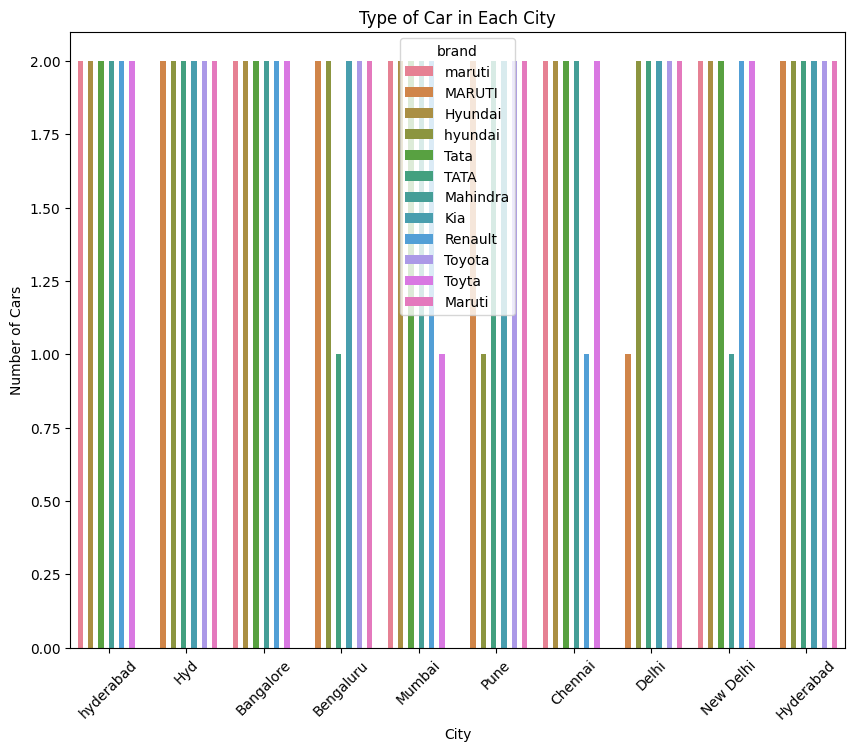

In [106]:
plt.figure(figsize=(10, 8))
sns.countplot(data=df, x="city", hue="brand")
plt.title("Type of Car in Each City")
plt.xlabel("City")
plt.ylabel("Number of Cars")
plt.xticks(rotation=45)
plt.show()

In [107]:
# 1st Standardize the lettercase
df['city'] = df['city'].str.strip().str.lower()

In [108]:
# Spelling Mistakes
df["city"] = df["city"].replace({"toyta":"toyota"})

In [109]:
# Univariate analysis
df["city"].value_counts()

,count
city,
hyderabad,24
hyd,12
bangalore,12
bengaluru,12
mumbai,12
pune,12
chennai,12
delhi,12
new delhi,12


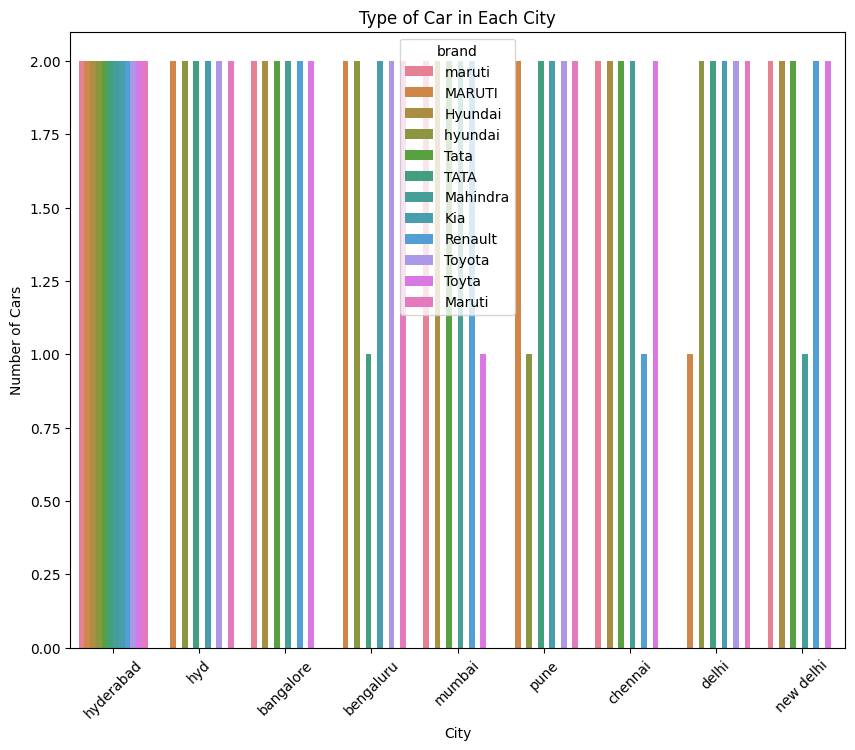

In [110]:
# Visualize
plt.figure(figsize=(10, 8))
sns.countplot(data=df, x="city", hue="brand")
plt.title("Type of Car in Each City")
plt.xlabel("City")
plt.ylabel("Number of Cars")
plt.xticks(rotation=45)
plt.show()

In [111]:
# Analysing the categorical variables
categorical_columns = df.select_dtypes(include = ["object"]).columns
print("Categorical columns:")
print(categorical_columns)

Categorical columns:
Index(['car_id', 'brand', 'model', 'year', 'km_driven', 'fuel_type',
       'transmission', 'owner_type', 'city', 'insurance_valid', 'listed_date'],
      dtype='object')


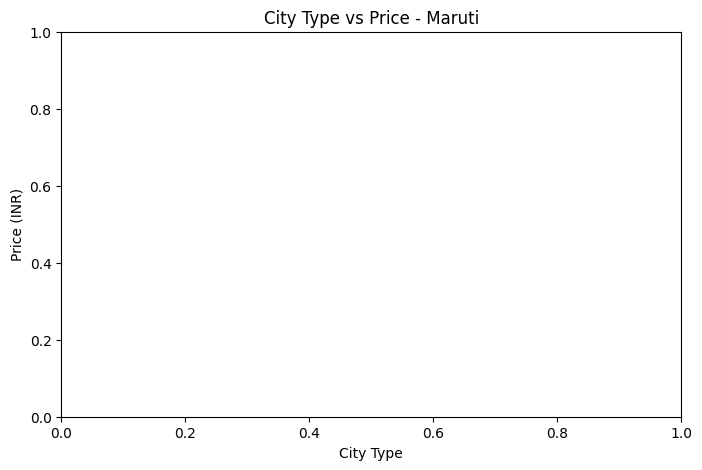

In [112]:
# Bivariate Analysis

maruti_df = df[df["brand"].astype(str).str.lower().str.strip() == "maruthi"]

plt.figure(figsize=(8, 5))

sns.barplot(
    data=maruti_df,
    x="city",
    y="price_inr",
    errorbar=None
)

plt.title("City Type vs Price - Maruti")
plt.xlabel("City Type")
plt.ylabel("Price (INR)")

plt.show()

In [113]:
print(df.columns)
print(df["brand"].unique())

Index(['car_id', 'brand', 'model', 'year', 'price_inr', 'km_driven',
       'fuel_type', 'transmission', 'owner_type', 'mileage_kmpl', 'engine_cc',
       'city', 'insurance_valid', 'seller_rating', 'listed_date'],
      dtype='object')
['maruti' 'MARUTI' 'Hyundai' 'hyundai ' 'Tata' 'TATA' 'Mahindra' 'Kia'
 'Renault' 'Toyota' 'Toyta' 'Maruti' nan]


In [114]:
# Analysing the categorical variables
categorical_columns = df.select_dtypes(include = ["object"]).columns
print("Categorical columns:")
print(categorical_columns)

Categorical columns:
Index(['car_id', 'brand', 'model', 'year', 'km_driven', 'fuel_type',
       'transmission', 'owner_type', 'city', 'insurance_valid', 'listed_date'],
      dtype='object')


In [115]:
# Unique values
for column in categorical_columns:
  print(
      column,
      ":",
      df[column].nunique(dropna = False),
      "\n"
  )

car_id : 120 

brand : 13 

model : 10 

year : 18 

km_driven : 37 

fuel_type : 7 

transmission : 5 

owner_type : 6 

city : 9 

insurance_valid : 3 

listed_date : 105 



In [116]:
for column in categorical_columns:
  print(
      column,
      ":",
      df[column].unique(),
      "\n"
  )

car_id : ['CAR001' 'CAR002' 'CAR003' 'CAR004' 'CAR005' 'CAR006' 'CAR007' 'CAR008'
 'CAR009' 'CAR010' 'CAR011' 'CAR012' 'CAR013' 'CAR014' 'CAR015' 'CAR016'
 'CAR017' 'CAR018' 'CAR019' 'CAR020' 'CAR021' 'CAR022' 'CAR023' 'CAR024'
 'CAR025' 'CAR026' 'CAR027' 'CAR028' 'CAR029' 'CAR030' 'CAR031' 'CAR032'
 'CAR033' 'CAR034' 'CAR035' 'CAR036' 'CAR037' 'CAR038' 'CAR039' 'CAR040'
 'CAR041' 'CAR042' 'CAR043' 'CAR044' 'CAR045' 'CAR046' 'CAR047' 'CAR048'
 'CAR049' 'CAR050' 'CAR051' 'CAR052' 'CAR053' 'CAR054' 'CAR055' 'CAR056'
 'CAR057' 'CAR058' 'CAR059' 'CAR060' 'CAR061' 'CAR062' 'CAR063' 'CAR064'
 'CAR065' 'CAR066' 'CAR067' 'CAR068' 'CAR069' 'CAR070' 'CAR071' 'CAR072'
 'CAR073' 'CAR074' 'CAR075' 'CAR076' 'CAR077' 'CAR078' 'CAR079' 'CAR080'
 'CAR081' 'CAR082' 'CAR083' 'CAR084' 'CAR085' 'CAR086' 'CAR087' 'CAR088'
 'CAR089' 'CAR090' 'CAR091' 'CAR092' 'CAR093' 'CAR094' 'CAR095' 'CAR096'
 'CAR097' 'CAR098' 'CAR099' 'CAR100' 'CAR101' 'CAR102' 'CAR103' 'CAR104'
 'CAR105' 'CAR106' 'CAR107' 'CAR108' 'CAR1

In [117]:
# let's clean categorical data
df_clean = df.copy()

In [118]:
# Extra Spaces in all text columns

text_columns = df_clean.select_dtypes(include = ["object"]).columns

for column in text_columns:
  df_clean[column] = df_clean[column].str.strip()

In [119]:
df["brand"] = df["brand"].fillna(df["brand"].mode()[0])

In [120]:
df["car_id"] = df["car_id"].fillna(df["car_id"].mode()[0])

In [121]:
df["price_inr"] = df["price_inr"].fillna(df["price_inr"].mode()[0])

In [122]:
# Fuel type
df_clean["fuel_type"] = df_clean["fuel_type"].str.title().str.lower()

In [123]:
#transimission
df_clean["transmission"] = df_clean["transmission"].str.title().str.lower().replace({"auto":"automatic"})

In [124]:
df_clean["insurance_valid"].value_counts()

,count
insurance_valid,
Yes,93
NO,27


In [125]:
df_clean["insurance_valid"].value_counts()

,count
insurance_valid,
Yes,93
NO,27


In [126]:
df_clean["year"] = pd.to_numeric(df_clean["year"],errors = "coerce")

In [127]:
df_clean["km_driven"] = (df_clean["km_driven"].str.replace(",","").str.replace("km","").astype(float))

In [128]:
df_clean["km_driven"].info()

<class 'pandas.core.series.Series'>
Index: 120 entries, 0 to 119
Series name: km_driven
Non-Null Count  Dtype  
--------------  -----  
120 non-null    float64
dtypes: float64(1)
memory usage: 1.9 KB


In [129]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 120 entries, 0 to 119
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   car_id           120 non-null    object 
 1   brand            114 non-null    object 
 2   model            120 non-null    object 
 3   year             116 non-null    float64
 4   price_inr        115 non-null    float64
 5   km_driven        120 non-null    float64
 6   fuel_type        120 non-null    object 
 7   transmission     120 non-null    object 
 8   owner_type       120 non-null    object 
 9   mileage_kmpl     120 non-null    float64
 10  engine_cc        120 non-null    float64
 11  city             120 non-null    object 
 12  insurance_valid  120 non-null    object 
 13  seller_rating    120 non-null    float64
 14  listed_date      120 non-null    object 
dtypes: float64(6), object(9)
memory usage: 15.0+ KB


In [130]:
df_clean.drop(columns = ["year","listed_date"],inplace = True)

In [131]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 120 entries, 0 to 119
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   car_id           120 non-null    object 
 1   brand            114 non-null    object 
 2   model            120 non-null    object 
 3   price_inr        115 non-null    float64
 4   km_driven        120 non-null    float64
 5   fuel_type        120 non-null    object 
 6   transmission     120 non-null    object 
 7   owner_type       120 non-null    object 
 8   mileage_kmpl     120 non-null    float64
 9   engine_cc        120 non-null    float64
 10  city             120 non-null    object 
 11  insurance_valid  120 non-null    object 
 12  seller_rating    120 non-null    float64
dtypes: float64(5), object(8)
memory usage: 13.1+ KB


In [132]:
print(df_clean.columns)

Index(['car_id', 'brand', 'model', 'price_inr', 'km_driven', 'fuel_type',
       'transmission', 'owner_type', 'mileage_kmpl', 'engine_cc', 'city',
       'insurance_valid', 'seller_rating'],
      dtype='object')


In [133]:
['name', 'year_of_manufacture', 'km_driven', 'owner_type', 'price_inr']

['name', 'year_of_manufacture', 'km_driven', 'owner_type', 'price_inr']

In [134]:
print(df_clean.columns.tolist())

['car_id', 'brand', 'model', 'price_inr', 'km_driven', 'fuel_type', 'transmission', 'owner_type', 'mileage_kmpl', 'engine_cc', 'city', 'insurance_valid', 'seller_rating']


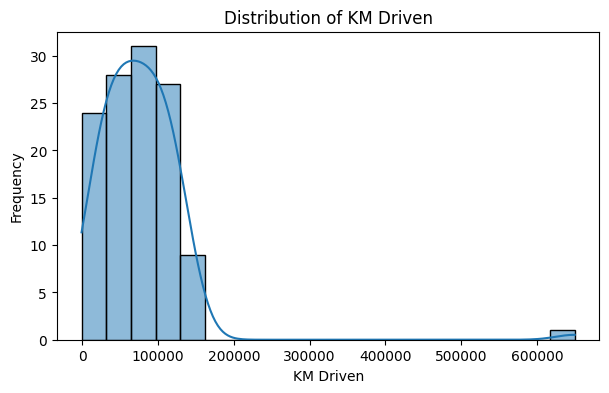

In [135]:
# Histogram
# Histogram
plt.figure(figsize=(7, 4))

sns.histplot(
    data=df_clean,
    x="km_driven",
    bins=20,
    kde=True
)

plt.title("Distribution of KM Driven")
plt.xlabel("KM Driven")
plt.ylabel("Frequency")
plt.show()

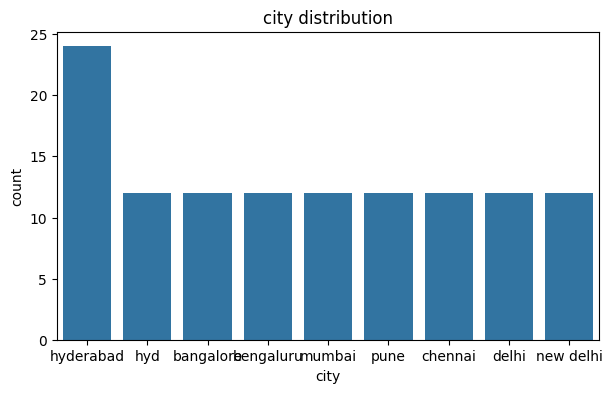

In [136]:
plt.figure(figsize = (7,4))
sns.countplot(data = df_clean,x = "city")
plt.title("city distribution")
plt.xlabel("city")
plt.ylabel("count")
plt.show()

In [137]:
df_clean.sort_values(by = "price_inr",ascending = False).head(10)

,car_id,brand,model,price_inr,km_driven,fuel_type,transmission,owner_type,mileage_kmpl,engine_cc,city,insurance_valid,seller_rating
16,CAR017,Tata,Kwid,9500000.0,82100.0,diesel,automatic,3rd,18.3,1000.0,chennai,Yes,4.7
46,CAR047,Toyta,Kwid,1306000.0,77800.0,electric,automatic,3rd,18.3,2200.0,chennai,Yes,3.5
94,CAR095,NaN,XUV300,1297000.0,17600.0,cng,manual,3rd,16.5,2200.0,mumbai,Yes,4.1
70,CAR071,Toyta,Baleno,1270000.0,47700.0,petrol,manual,3rd,12.9,2200.0,hyderabad,Yes,3.8
117,CAR118,Toyota,Innova,1268000.0,116500.0,petrol,automatic,Third,19.2,2000.0,delhi,Yes,4.3
118,CAR119,Toyta,Altroz,1261000.0,120800.0,petrol,automatic,3rd,20.1,2200.0,new delhi,Yes,4.4
93,CAR094,Toyota,Nexon,1241000.0,13300.0,diesel,automatic,Third,15.6,2000.0,bengaluru,Yes,4.0
21,CAR022,Toyota,i20,1223000.0,103600.0,petrol,automatic,Third,13.8,2000.0,hyd,Yes,8.7
69,CAR070,Toyota,Swift,1214000.0,43400.0,petrol,manual,Third,12.0,2000.0,hyderabad,Yes,3.7
116,CAR117,Renault,Kwid,1212000.0,112200.0,electric,automatic,2nd,18.3,1800.0,chennai,Yes,4.2


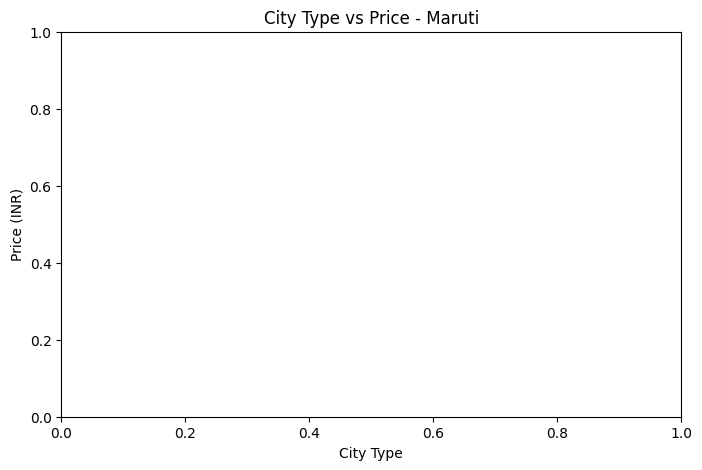

In [138]:
# Bivariate Analysis

maruti_df = df[df["brand"].astype(str).str.lower().str.strip() == "maruthi"]

plt.figure(figsize=(8, 5))

sns.barplot(
    data=maruti_df,
    x="city",
    y="price_inr",
    errorbar=None
)

plt.title("City Type vs Price - Maruti")
plt.xlabel("City Type")
plt.ylabel("Price (INR)")

plt.show()

In [139]:
numeric_data = df_clean.select_dtypes(include = "number")
# calculate correaltion
correlation = numeric_data.corr()
correlation

,price_inr,km_driven,mileage_kmpl,engine_cc,seller_rating
price_inr,1.000000,0.041488,0.082202,0.020690,0.103467
km_driven,0.041488,1.000000,0.093338,-0.092275,0.314186
mileage_kmpl,0.082202,0.093338,1.000000,0.041437,-0.088030
engine_cc,0.020690,-0.092275,0.041437,1.000000,0.007067
seller_rating,0.103467,0.314186,-0.088030,0.007067,1.000000


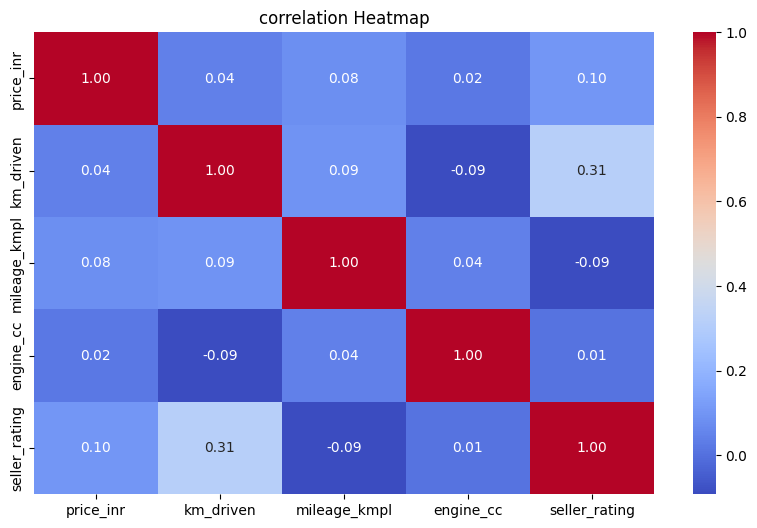

In [140]:
# Multi variate analysis
plt.figure(figsize= (10,6))
sns.heatmap(correlation,annot = True, cmap = "coolwarm", fmt = ".2f" )
plt.title("correlation Heatmap")
plt.show()

In [141]:
numeric_columns = ["price_inr","km_driven","mileage_kmpl","engine_cc","seller_rating"]

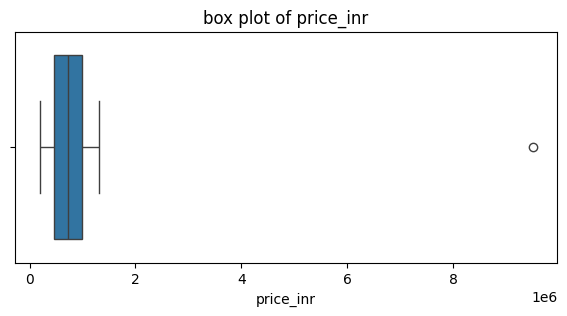

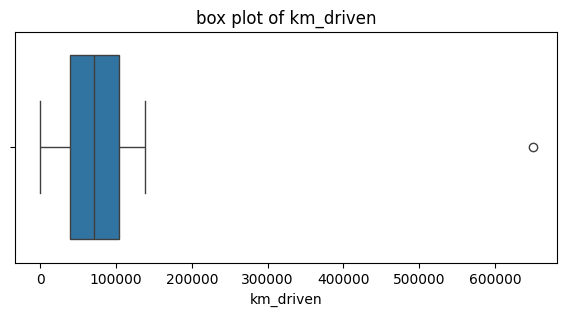

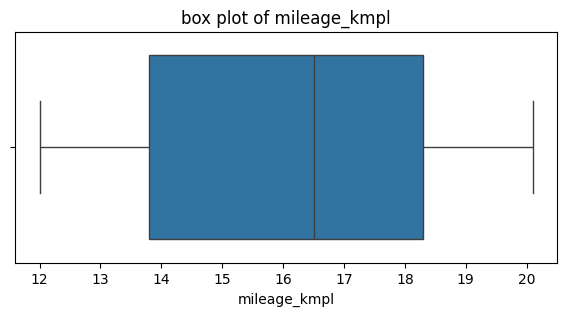

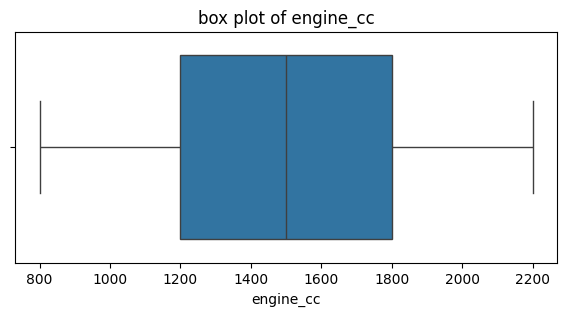

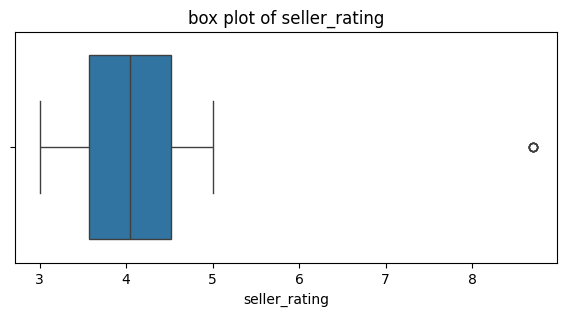

In [142]:
for i in numeric_columns:
  plt.figure(figsize = (7,3))
  sns.boxplot(x = df_clean[i])
  plt.title(f"box plot of {i}")
  plt.show()

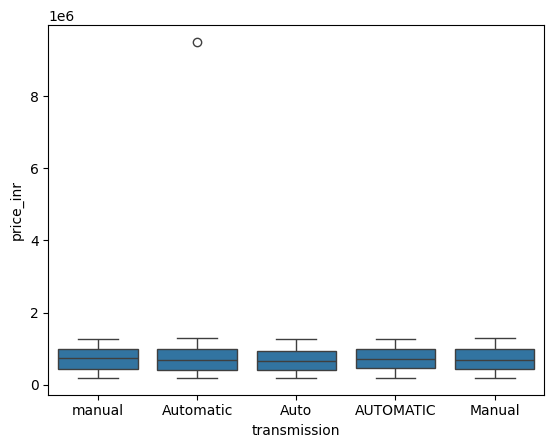

transmission
AUTOMATIC    7.220000e+05
Auto         6.814783e+05
Automatic    1.068870e+06
Manual       7.095417e+05
manual       7.113478e+05
Name: price_inr, dtype: float64


In [143]:
#Transmission vs Car Price
sns.boxplot(data=df, x="transmission", y="price_inr")
plt.show()#

print(df.groupby("transmission")["price_inr"].mean())

brand
Tata        1.573400e+06
Toyota      8.538000e+05
Toyta       8.495556e+05
Renault     8.286667e+05
Kia         7.728000e+05
TATA        7.436667e+05
Hyundai     7.291875e+05
hyundai     7.023333e+05
Mahindra    6.824444e+05
MARUTI      5.496667e+05
Name: price_inr, dtype: float64


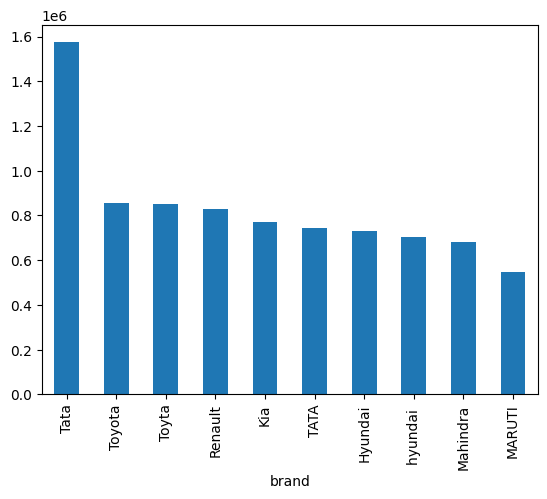

In [144]:
# Top 10 Brands by Average Price
avg_price = df.groupby("brand")["price_inr"].mean().sort_values(ascending=False)

print(avg_price.head(10))
avg_price.head(10).plot(kind="bar")
plt.show()

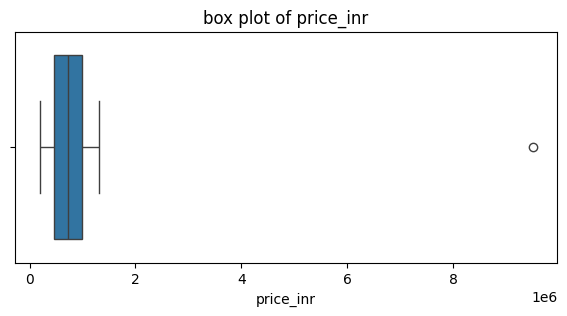

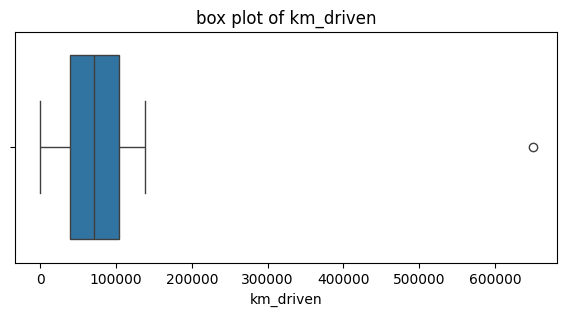

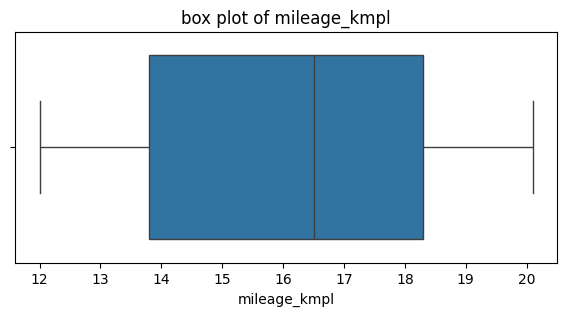

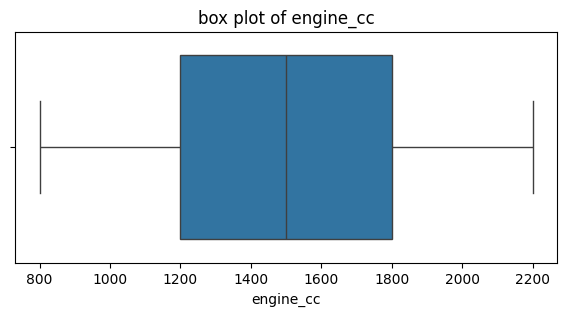

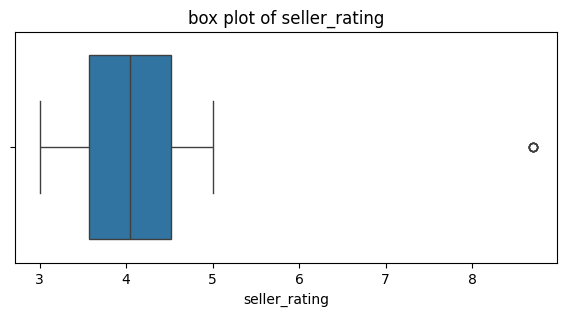

In [145]:
for i in numeric_columns:
  plt.figure(figsize = (7,3))
  sns.boxplot(x = df_clean[i])
  plt.title(f"box plot of {i}")
  plt.show()

In [146]:
# Find the index containing the highest ADR
outlier_index = df_clean["price_inr"].idxmax()

# Drop the outlier
df_clean.drop(outlier_index, inplace=True)

# Reset the index
df_clean.reset_index(drop=True, inplace=True)

In [147]:
#Identifying Outliers

numeric_cols_for_outliers = df_clean.select_dtypes(include=np.number).columns.tolist()

for col in numeric_cols_for_outliers:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df_clean[(df_clean[col] < lower_bound) | (df_clean[col] > upper_bound)]

    print(f"Column: {col}")
    print(f"  Q1: {Q1}, Q3: {Q3}, IQR: {IQR}")
    print(f"  Lower Bound: {lower_bound}, Upper Bound: {upper_bound}")
    print(f"  Number of outliers: {len(outliers)}")
    if not outliers.empty:
        print("  Outlier values (first 5 if many):\n", outliers[[col]].head())
    print("\n" + "-"*50 + "\n")


Column: price_inr
  Q1: 453250.0, Q3: 985250.0, IQR: 532000.0
  Lower Bound: -344750.0, Upper Bound: 1783250.0
  Number of outliers: 0

--------------------------------------------------

Column: km_driven
  Q1: 39100.0, Q3: 103600.0, IQR: 64500.0
  Lower Bound: -57650.0, Upper Bound: 200350.0
  Number of outliers: 1
  Outlier values (first 5 if many):
     km_driven
86   650000.0

--------------------------------------------------

Column: mileage_kmpl
  Q1: 13.8, Q3: 18.3, IQR: 4.5
  Lower Bound: 7.050000000000001, Upper Bound: 25.05
  Number of outliers: 0

--------------------------------------------------

Column: engine_cc
  Q1: 1200.0, Q3: 1800.0, IQR: 600.0
  Lower Bound: 300.0, Upper Bound: 2700.0
  Number of outliers: 0

--------------------------------------------------

Column: seller_rating
  Q1: 3.55, Q3: 4.5, IQR: 0.9500000000000002
  Lower Bound: 2.1249999999999996, Upper Bound: 5.925000000000001
  Number of outliers: 5
  Outlier values (first 5 if many):
      seller_r

In [148]:
# Capping outliers using IQR bounds

for col in numeric_cols_for_outliers:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    df_clean[col] = np.where(df_clean[col] < lower_bound, lower_bound, df_clean[col])
    df_clean[col] = np.where(df_clean[col] > upper_bound, upper_bound, df_clean[col])

print("Outliers have been capped in the numeric columns.")

Outliers have been capped in the numeric columns.


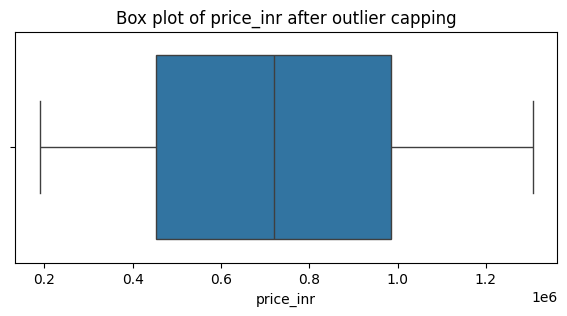

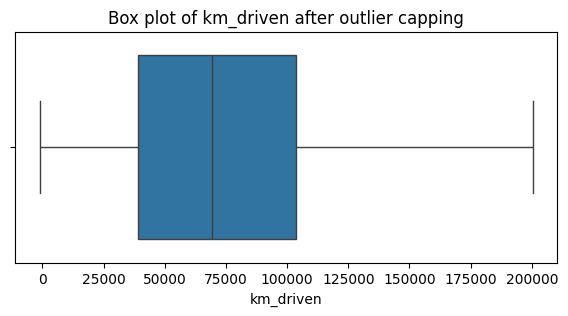

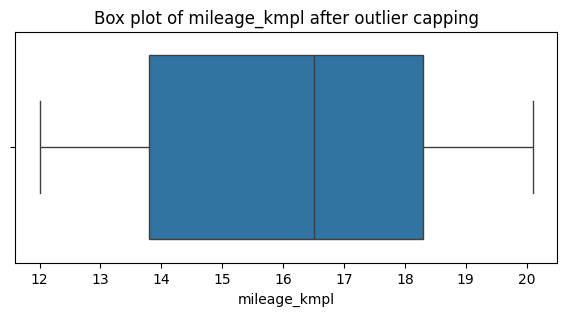

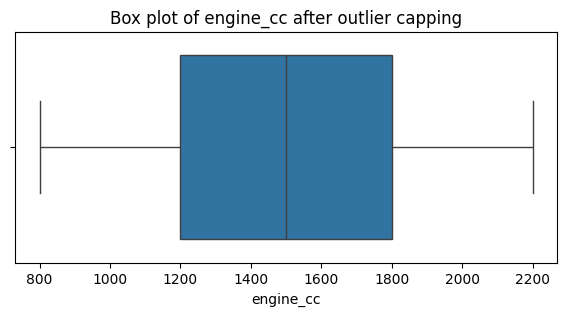

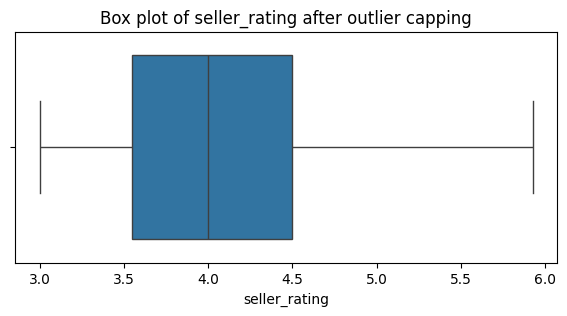

In [149]:
for i in numeric_cols_for_outliers:
  plt.figure(figsize = (7,3))
  sns.boxplot(x = df_clean[i])
  plt.title(f"Box plot of {i} after outlier capping")
  plt.show()

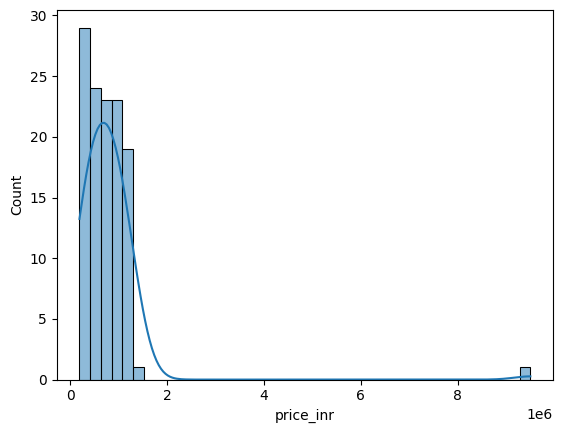

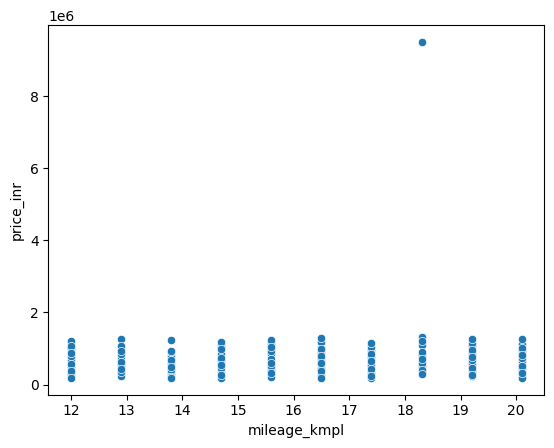

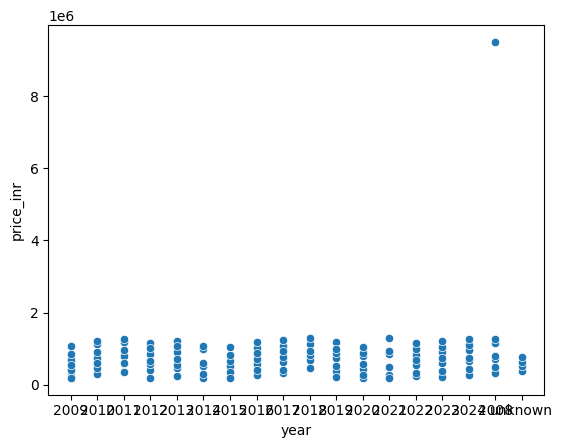

Average Car Price: 776183.3333333334


In [150]:
# Simple Car EDA
sns.histplot(df["price_inr"], kde=True)
plt.show()

sns.scatterplot(data=df, x="mileage_kmpl", y="price_inr")
plt.show()

sns.scatterplot(data=df, x="year", y="price_inr")
plt.show()

print("Average Car Price:", df["price_inr"].mean())

In [151]:
# find the index containing the highest price
outlier_index = df_clean["price_inr"].idxmax()
df_clean.drop(outlier_index,inplace = True)
df_clean.reset_index(drop = True, inplace = True)

In [152]:
print("new maximum price:",df_clean["price_inr"].max())

new maximum price: 1297000.0


In [153]:
# find the index containing the highest price
outlier_index = df_clean["seller_rating"].idxmin()
df_clean.drop(outlier_index,inplace = True)
df_clean.reset_index(drop = True, inplace = True)

In [154]:
print("new brand:",df_clean["seller_rating"].min())

new brand: 3.0


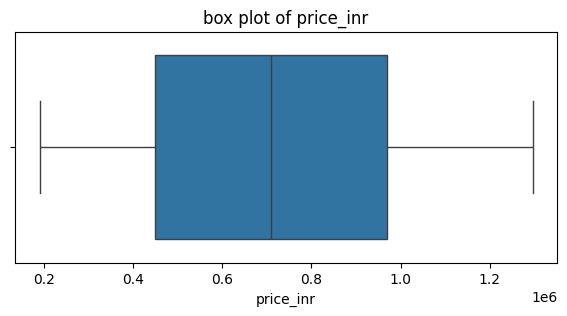

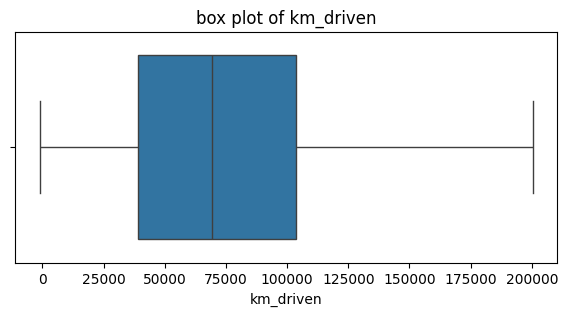

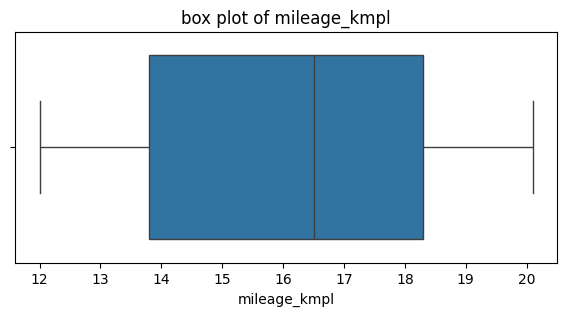

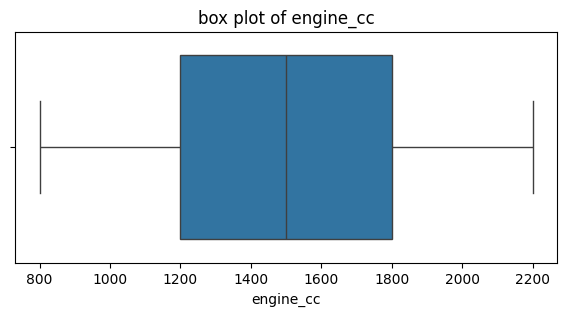

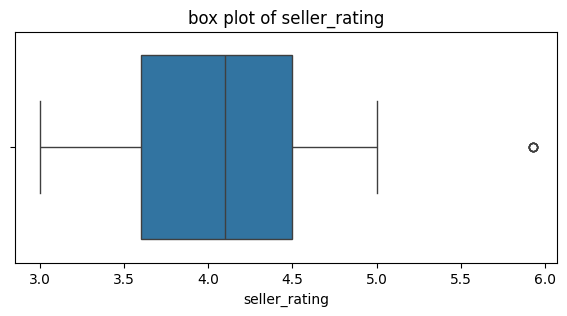

In [155]:
for i in numeric_columns:
  plt.figure(figsize = (7,3))
  sns.boxplot(x = df_clean[i])
  plt.title(f"box plot of {i}")
  plt.show()

In [156]:
#Outlier removal
Q1 = df_clean["price_inr"].quantile(0.25)
Q3 = df_clean["price_inr"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("lower limit:", lower_bound)
print("upper limit:", upper_bound)

lower limit: -333500.0
upper limit: 1752500.0


In [157]:
df = df_clean[(df_clean["price_inr"]>= lower_bound)&(df_clean["price_inr"]<= upper_bound)]

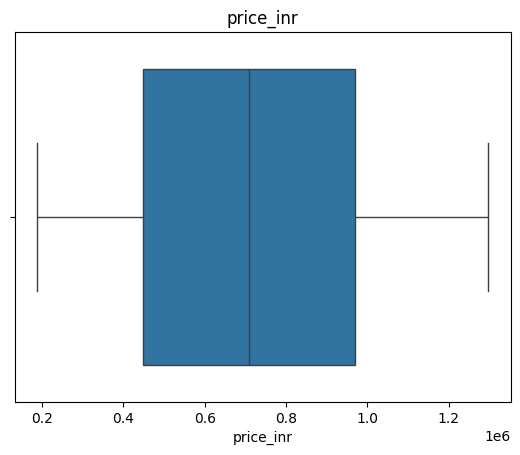

In [158]:
sns.boxplot(x = df_clean["price_inr"])
plt.title("price_inr")
plt.show()

In [159]:
df = df_clean[
    (df_clean["price_inr"] >= lower_bound) &
    (df_clean["price_inr"] <= upper_bound)
]

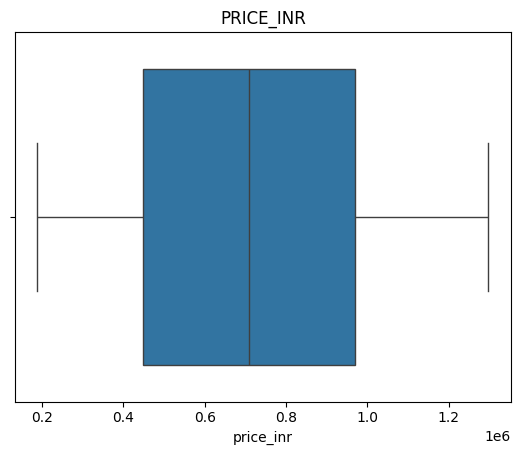

In [160]:
sns.boxplot(x=df_clean["price_inr"])

plt.title("PRICE_INR")

plt.show()

In [161]:
categorical_columns = df_clean.select_dtypes(include='object').columns

df_clean = pd.get_dummies(
    df_clean,
    columns=categorical_columns,
    drop_first=True,
    dtype=int
)

In [162]:
df_clean.loc[df_clean["price_inr"].idxmax()]

,91
price_inr,1297000.0
km_driven,17600.0
mileage_kmpl,16.5
engine_cc,2200.0
seller_rating,4.1
...,...
city_hyderabad,0.0
city_mumbai,1.0
city_new delhi,0.0
city_pune,0.0


In [163]:
x="year"

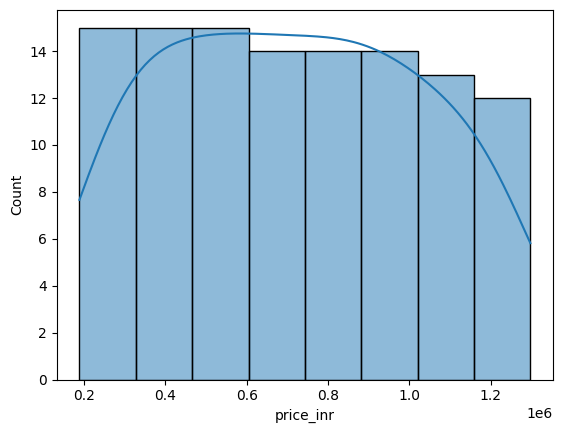

In [164]:
sns.histplot(df["price_inr"], kde=True)
plt.show()

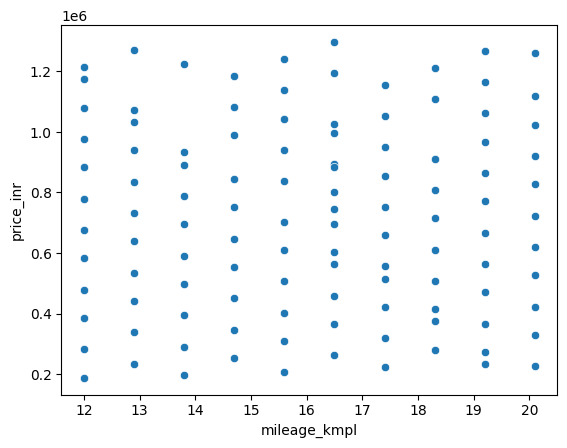

Average Car Price: 716285.7142857143


In [165]:
sns.scatterplot(data=df, x="mileage_kmpl", y="price_inr")
plt.show()

print("Average Car Price:", df["price_inr"].mean())

In [166]:
# Convert whole-number columns to integer

integer_columns = ['price_inr',
'km_driven',
'mileage_kmpl',
'engine_cc',
'seller_rating',
'city_hyderabad',
'city_mumbai',
'city_new delhi',
'city_pune',
'insurance_valid_Yes',]
for column in integer_columns:
    if column in df_clean.columns:
        df_clean[column] = (
            pd.to_numeric(df_clean[column], errors='coerce')
            .fillna(0)
            .round()
            .astype(int)
        )

print('Final shape:', df_clean.shape)
print('Missing values:', df_clean.isnull().sum().sum())
print('Duplicate rows:', df_clean.duplicated().sum())
print('Object columns:', len(df_clean.select_dtypes(include='object').columns))

df_clean.info()
df_clean.head()

Final shape: (117, 159)
Missing values: 0
Duplicate rows: 0
Object columns: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 117 entries, 0 to 116
Columns: 159 entries, price_inr to insurance_valid_Yes
dtypes: int64(159)
memory usage: 145.5 KB


,price_inr,km_driven,mileage_kmpl,engine_cc,seller_rating,car_id_CAR002,car_id_CAR003,car_id_CAR004,car_id_CAR005,car_id_CAR006,...,owner_type_Third,city_bengaluru,city_chennai,city_delhi,city_hyd,city_hyderabad,city_mumbai,city_new delhi,city_pune,insurance_valid_Yes
0,236000,13300,13,1000,3,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,1
1,292000,17600,14,1200,3,1,0,0,0,0,...,0,0,0,0,1,0,0,0,0,1
2,348000,21900,15,1400,3,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,1
3,404000,26200,16,1600,3,0,0,1,0,0,...,1,1,0,0,0,0,0,0,0,0
4,460000,30500,16,1800,4,0,0,0,1,0,...,0,0,0,0,0,0,1,0,0,1


In [167]:
df_clean.to_csv('/content/uncleaned_used_cars_eda (1) (1).csv', index=False)

print('Saved as uncleaned_used_cars_eda (1) (1).csv')

Saved as uncleaned_used_cars_eda (1) (1).csv
